# Lepton-jet reconstruction efficiency, step 2: data against simulation in the control samples

The data part of step 2 of [`lj_reco_efficiency.md`](lj_reco_efficiency.md): the passing fraction
of the probes of the two control samples in data, against the simulation of
[`07_lj_reco_control_samples.ipynb`](07_lj_reco_control_samples.ipynb).

**Data.** Campaign `lj_reco_cr_data_v1`: all 2018 DoubleMuon files, the `_alone` versions of the
two control samples only, so no event of the signal region enters. The advisor approved reading
data in these control samples, each thought through before its first look. The data are read only
through `systematics_study.lj_cr_data`, which takes the safety table that notebook 07 wrote to EOS
and stops unless every region it reads is safe; notebook 07 found every region of both samples safe.

**The comparison.** For each control sample, the passing fraction after the sideband subtraction
(`systematics_study.probe_efficiency`), in data and in the simulated background:

* $J/\psi \to \mu\mu$ (muon-type lepton jets): against the pair $p_T$, the opening angle
  $\Delta R(\mu\mu)$ and $|\eta|$;
* $Z \to \mu\mu\gamma$ (egamma-type lepton jets): for unconverted photons ($R_9 \geq 0.94$) above
  30 GeV, where notebook 07 showed that the subtraction gives the same efficiency whatever the
  background, against the photon $p_T$ and $|\eta|$.

The simulation keeps the provisional lepton scale factors, so the data/simulation ratios measure
what they miss.

In [1]:
import os, shutil, sys, tempfile, json, warnings
from pathlib import Path
import numpy as np
import hist
import matplotlib.pyplot as plt

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy
import plot_tools as pt   # on the path through systematics_study  # pylint: disable=import-error

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)

DATA_DIR = sysstudy.eos_url(sysstudy.LJ_CR_DATA_DIR)              # merged outputs of lj_reco_cr_data_v1
SIM_DIR = sysstudy.eos_url(sysstudy.LJ_CR_DIR)                    # merged outputs of lj_reco_cr_v2
OUTPUT_DIR = sysstudy.eos_url(sysstudy.LJ_CR_DATA_RESULTS_DIR)    # figures and passing fractions
if not sysstudy.list_coffea(DATA_DIR):
    raise FileNotFoundError(f"No merged outputs in {DATA_DIR} yet: run the campaign lj_reco_cr_data_v1 "
                            "(condor/README.md, section 23)")
WORK = Path(tempfile.mkdtemp(prefix="lj_reco_cr_data_v1_"))   # removed at the end
# the Z -> mumu gamma probes compared: unconverted photons above 30 GeV
Z_SELECTION = {"probe_pt": slice(hist.loc(30), None, sum), "probe_r9": slice(hist.loc(0.94), None, sum)}


def save(fig, name):
    """Write a figure into the working directory, for EOS, as PDF and PNG"""
    for suffix in (".pdf", ".png"):
        fig.savefig(WORK / f"{name}{suffix}", bbox_inches="tight")


print("data:      ", DATA_DIR)
print("simulation:", SIM_DIR)
print("outputs:   ", OUTPUT_DIR)

data:       root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_data_v1
simulation: root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_v2
outputs:    root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_data_v1_results


## 1. Inputs, through the safety table

The safety table of notebook 07 is read back first (`lj_cr_verdicts`, which also checks that it was
judged with the current sparse-bin rule); `lj_cr_data` then reads the data, refusing any region the
table does not mark safe and setting such regions to zero before anything else is done with them.
Below, per control sample, the probes in the peak and after the sideband subtraction, in data and
in the simulation.

In [2]:
rows = sysstudy.lj_cr_verdicts(sysstudy.LJ_CR_RESULTS_DIR)
for cr in sysstudy.LJ_CR:
    print(f"{cr}: readable regions: {len(sysstudy.lj_cr_readable(rows, cr))}")
data = sysstudy.lj_cr_data(rows, DATA_DIR)
sim = sysstudy.lj_cr_inputs(SIM_DIR)
sim_total = {cr: sum(per[cr] for per in sim["background"].values()) for cr in sysstudy.LJ_CR}
print()
for cr, spec in sysstudy.LJ_CR.items():
    (lo, hi), sidebands = spec["peak"], spec["sidebands"]
    k = (hi - lo) / sum(b - a for a, b in sidebands)
    for label, h in (("data", data[cr]), ("simulation", sim_total[cr])):
        peak = sysstudy.mass_window(h, spec["mass"], lo, hi).sum(flow=True).value
        side = sum(sysstudy.mass_window(h, spec["mass"], a, b).sum(flow=True).value for a, b in sidebands)
        print(f"{cr:16s} {label:10s}: {peak:10.4g} probes in the peak, {peak - k * side:10.4g} after the subtraction")

Z -> mumu gamma: readable regions: 10
J/psi -> mumu: readable regions: 10



Z -> mumu gamma  data      :  2.033e+04 probes in the peak,  1.062e+04 after the subtraction
Z -> mumu gamma  simulation:   1.84e+04 probes in the peak,       9966 after the subtraction
J/psi -> mumu    data      :   4.05e+05 probes in the peak,  3.271e+05 after the subtraction
J/psi -> mumu    simulation:  4.803e+05 probes in the peak,  3.818e+05 after the subtraction


**Interpretation (run of 2026-11-17: `lj_reco_cr_data_v1`, all 68 data samples; simulation
`lj_reco_cr_v2`).** All ten regions of each sample are readable, so the data are read in full.
After the sideband subtraction the data hold 10,620 $Z \to \mu\mu\gamma$ probes against 9,966 in
the simulation (a ratio of 1.07), and 327,000 $J/\psi$ probes against 382,000 (0.86): the
simulation describes both yields within 15%, which the passing fractions do not depend on.

## 2. The probe mass in data and simulation

The simulation at its luminosity, stacked by process; the data as points. For the $Z$, the
probes compared in section 4 (unconverted photons above 30 GeV), passing and failing.

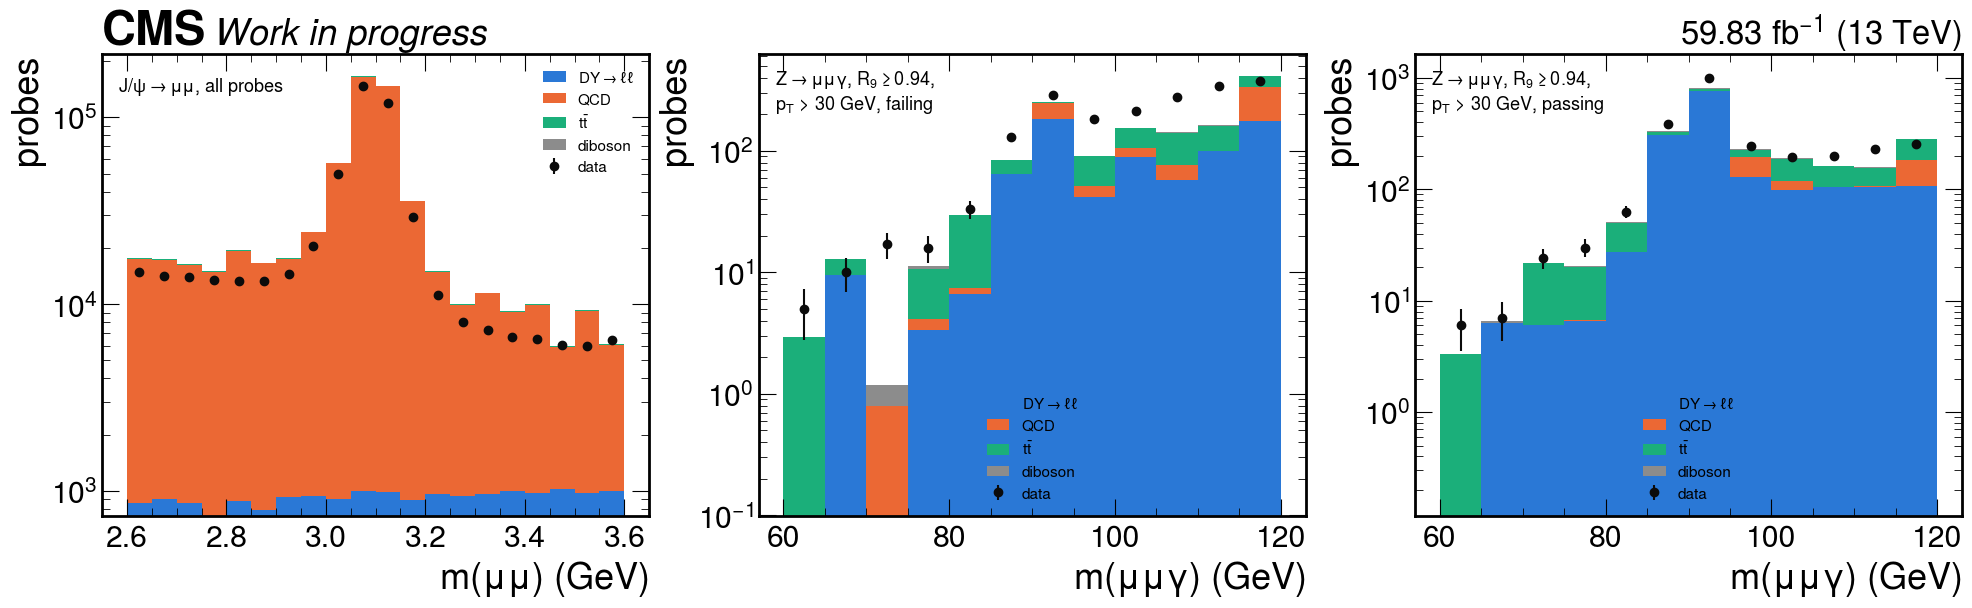

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
sysstudy.plot_mass_data_mc(data, sim, "J/psi -> mumu", ax=axes[0])
axes[0].text(0.03, 0.92, sysstudy.LJ_CR["J/psi -> mumu"]["label"] + ", all probes", transform=axes[0].transAxes, fontsize=13)
for ax, passing, title in ((axes[1], 0, "failing"), (axes[2], 1, "passing")):
    sysstudy.plot_mass_data_mc(data, sim, "Z -> mumu gamma", sel={**Z_SELECTION, "passing": passing}, ax=ax)
    ax.text(0.03, 0.88, sysstudy.LJ_CR["Z -> mumu gamma"]["label"] + rf", $R_9 \geq 0.94$," + "\n" + rf"$p_T$ > 30 GeV, {title}",
            transform=ax.transAxes, fontsize=13)
for ax in axes:
    ax.set_yscale("log")
pt.cms_label(axes, data=True, text="Work in progress")
save(fig, "mass_data_simulation")
plt.show()

**Interpretation.** The $J/\psi$ peak has the same shape in data and simulation, with the
simulation about 15% higher in the peak and the sidebands alike. Among the unconverted photons
above 30 GeV, the passing probes peak at the Z mass in data as in the simulation; the failing
probes hold more events in data than in the simulation above the peak, photons that do not come
from the Z, which the adjacent sidebands remove.

## 3. Muon-type lepton jets: $J/\psi \to \mu\mu$

The passing fraction in data and in the simulated background against the pair $p_T$, the opening
angle and $|\eta|$, and their ratio.

J/psi -> mumu against probe_pt:  low-high: data | simulation | data/simulation
   20-30: 0.379 +- 0.033 | 1.318 +- 1.579 | 0.288 +- 0.346
   30-40: 0.691 +- 0.009 | 0.746 +- 0.106 | 0.926 +- 0.133
   40-50: 0.818 +- 0.006 | 0.936 +- 0.043 | 0.874 +- 0.040
   50-60: 0.964 +- 0.001 | 0.962 +- 0.015 | 1.002 +- 0.016
   60-80: 0.985 +- 0.001 | 1.003 +- 0.012 | 0.982 +- 0.012
   80-100: 0.986 +- 0.001 | 0.996 +- 0.004 | 0.989 +- 0.004
   100-150: 0.987 +- 0.001 | 0.990 +- 0.004 | 0.997 +- 0.004
   150-300: 0.987 +- 0.006 | 1.015 +- 0.059 | 0.973 +- 0.057
J/psi -> mumu against probe_dR:  low-high: data | simulation | data/simulation
   0-0.01: nan +- nan | nan +- nan | nan +- nan
   0.01-0.02: 0.773 +- 0.139 | 0.321 +- 0.245 | 2.405 +- 1.886
   0.02-0.03: 0.926 +- 0.031 | 0.871 +- 0.057 | 1.063 +- 0.078
   0.03-0.05: 0.988 +- 0.004 | 1.008 +- 0.032 | 0.980 +- 0.031
   0.05-0.08: 0.989 +- 0.001 | 0.996 +- 0.002 | 0.993 +- 0.002
   0.08-0.12: 0.986 +- 0.000 | 0.991 +- 0.003 | 0.994 +- 0.003
  

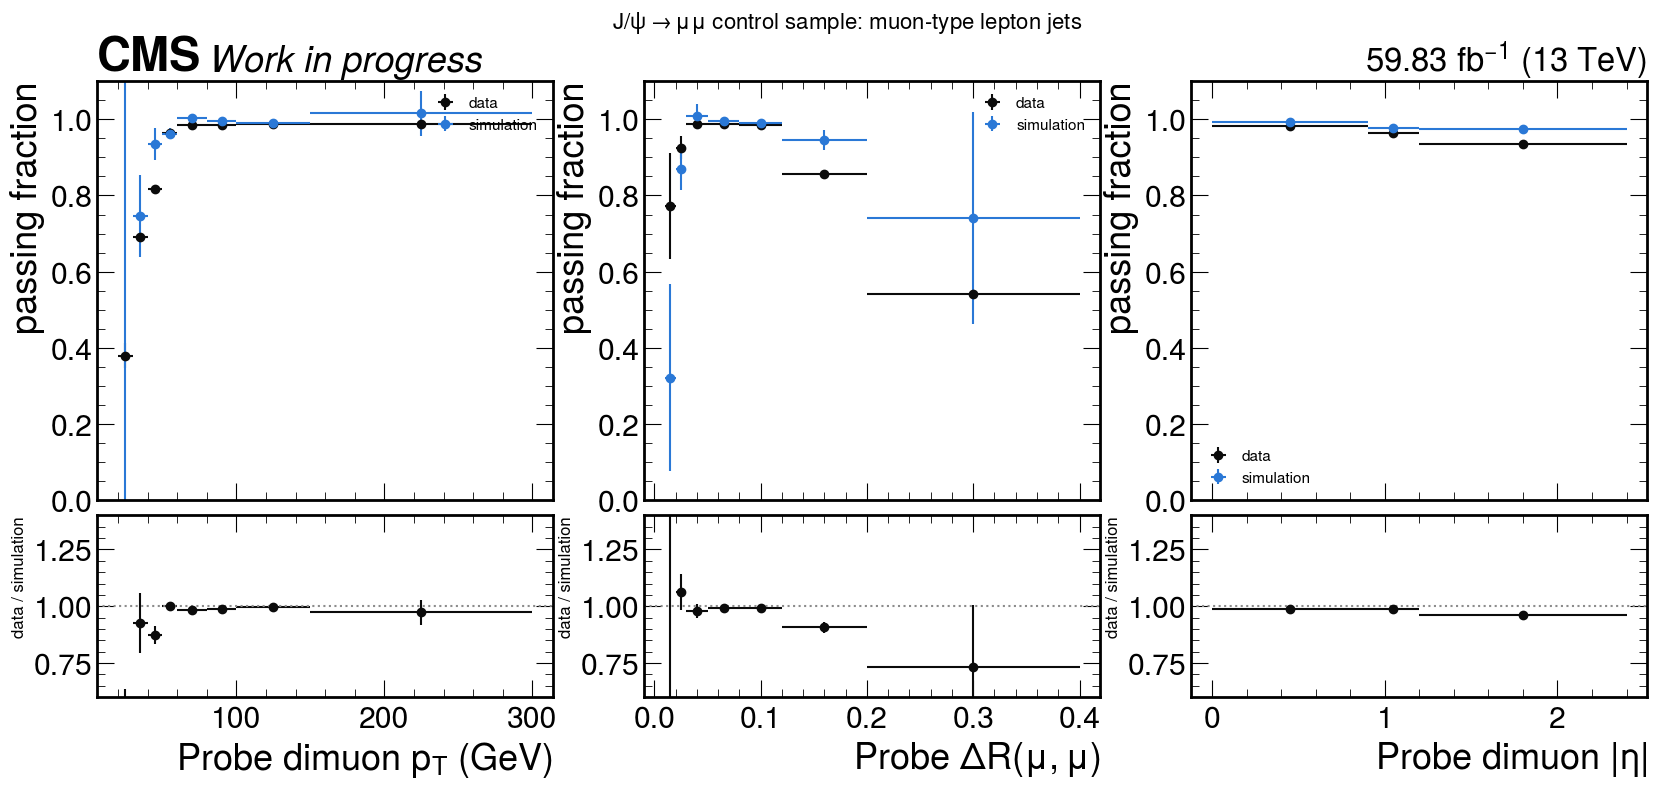

In [4]:
spec = spec_j = sysstudy.LJ_CR["J/psi -> mumu"]
tables = {}
fig, axes = plt.subplots(2, 3, figsize=(20, 8), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05})
for col, axis in enumerate(("probe_pt", "probe_dR", "probe_abseta")):
    results = {"data": sysstudy.probe_efficiency(data["J/psi -> mumu"], spec, axis),
               "simulation": sysstudy.probe_efficiency(sim_total["J/psi -> mumu"], spec, axis)}
    sysstudy.plot_efficiency_comparison(results, "simulation", axes[0, col], axes[1, col])
    tables[("J/psi -> mumu", axis)] = sysstudy.efficiency_table(results, "simulation")
    print(f"J/psi -> mumu against {axis}:  low-high: data | simulation | data/simulation")
    for lo, hi, d, de, s, se, r, re in tables[("J/psi -> mumu", axis)]:
        print(f"   {lo:g}-{hi:g}: {d:.3f} +- {de:.3f} | {s:.3f} +- {se:.3f} | {r:.3f} +- {re:.3f}")
fig.suptitle(f"{spec['label']} control sample: {spec['lj_type']} lepton jets", fontsize=16, y=0.97)
pt.cms_label(axes[0], data=True, text="Work in progress")
save(fig, "efficiency_jpsi_data_simulation")
plt.show()

**Interpretation.** Above 50 GeV the passing fraction is 0.96 to 0.99 in data and agrees
with the simulation within 1 to 2% in every bin: data/simulation 1.002 ± 0.016, 0.982 ± 0.012,
0.989 ± 0.004, 0.997 ± 0.004 and 0.97 ± 0.06 from 50 to 300 GeV. Near the 30 GeV threshold of the
lepton jets the data turn on more slowly (0.87 ± 0.04 from 40 to 50 GeV). Inside a wide bin near a
threshold the passing fraction depends on the $p_T$ spectrum within the bin, which differs between
the prompt and non-prompt $J/\psi$ of the data and the non-prompt ones of the simulation, so this
region does not give a scale factor. The large opening angles ($\Delta R \geq 0.12$) are the
low-$p_T$ pairs ($\Delta R \approx 2m/p_T$) and show the same threshold.

Away from the 30 GeV threshold of the lepton jets, whose turn-on depends on the $p_T$ spectrum
inside each bin (which differs between the prompt and non-prompt $J/\psi$ of the data and the
non-prompt ones of the simulation): the $p_T$ dependence from the threshold on, then the passing
fraction against the opening angle and $|\eta|$ for pairs above 50 GeV, and for all of them
together.

J/psi -> mumu, pT > 50 GeV, against probe_dR:  data | simulation | data/simulation
   0-0.01: nan +- nan | nan +- nan | nan +- nan
   0.01-0.02: 0.773 +- 0.139 | 0.321 +- 0.245 | 2.405 +- 1.886
   0.02-0.03: 0.926 +- 0.031 | 0.871 +- 0.057 | 1.063 +- 0.078
   0.03-0.05: 0.988 +- 0.004 | 1.008 +- 0.032 | 0.980 +- 0.031
   0.05-0.08: 0.989 +- 0.001 | 0.996 +- 0.002 | 0.993 +- 0.002
   0.08-0.12: 0.985 +- 0.000 | 0.991 +- 0.003 | 0.994 +- 0.003
   0.12-0.2: 0.832 +- 0.008 | 0.885 +- 0.056 | 0.940 +- 0.060
   0.2-0.4: 0.034 +- 0.060 | nan +- nan | nan +- nan
J/psi -> mumu, pT > 50 GeV, against probe_abseta:  data | simulation | data/simulation
   0-0.9: 0.991 +- 0.000 | 1.000 +- 0.009 | 0.991 +- 0.009
   0.9-1.2: 0.979 +- 0.001 | 0.985 +- 0.007 | 0.994 +- 0.007
   1.2-2.4: 0.959 +- 0.001 | 0.983 +- 0.008 | 0.976 +- 0.008
all probes above 50 GeV: data 0.9819 +- 0.0004, simulation 0.9936 +- 0.0062, data/simulation 0.988 +- 0.006


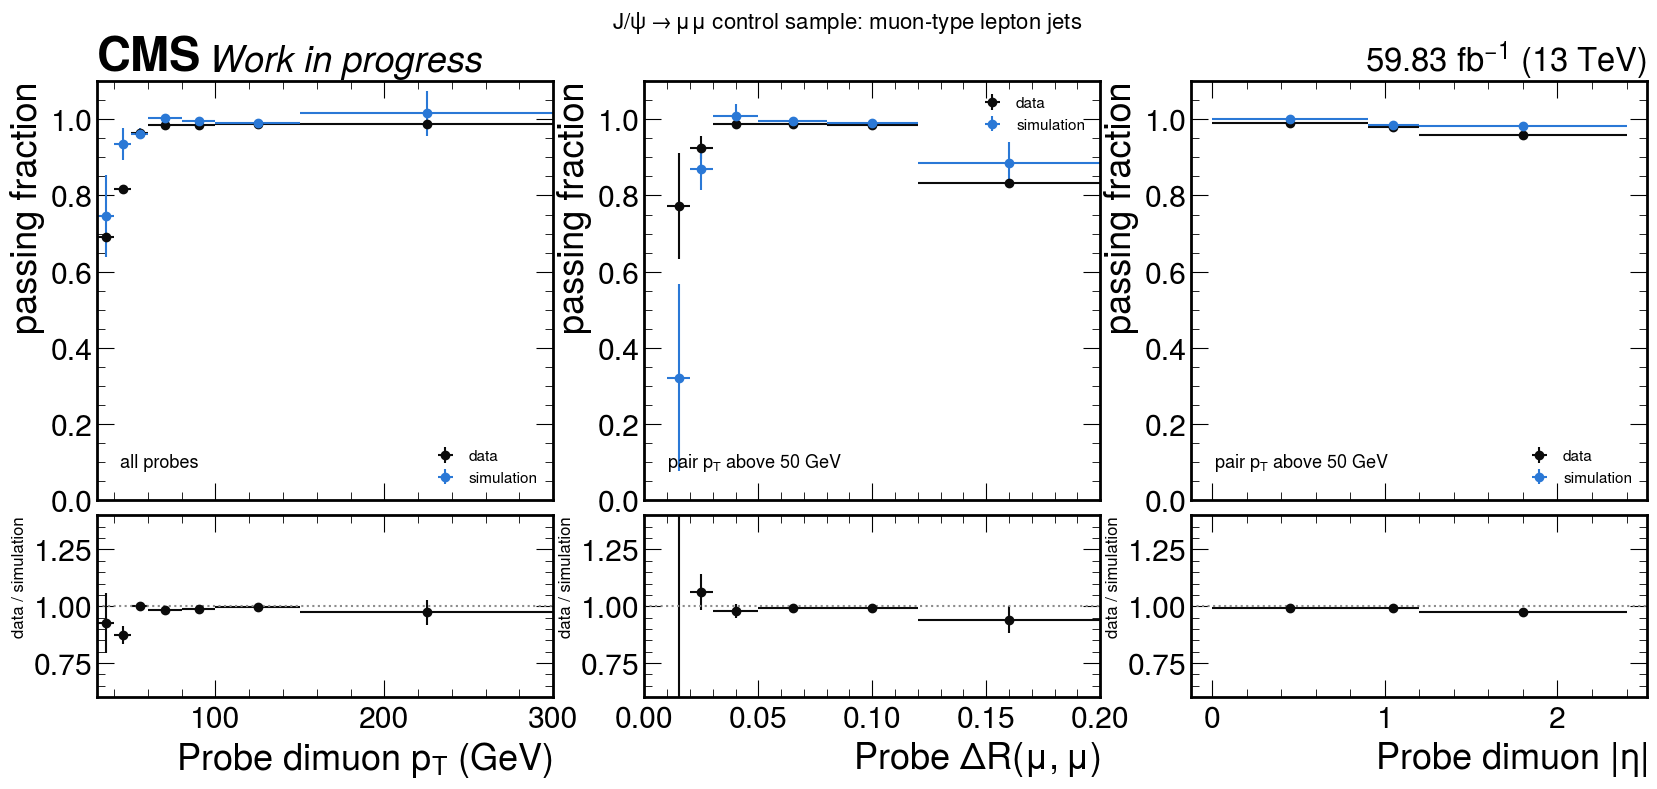

In [5]:
above = {"probe_pt": slice(hist.loc(50), None, sum)}
fig, axes = plt.subplots(2, 3, figsize=(20, 8), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05})
# the pT dependence from the lepton-jet threshold on, then the other axes above 50 GeV
results = {"data": sysstudy.probe_efficiency(data["J/psi -> mumu"], spec_j, "probe_pt"),
           "simulation": sysstudy.probe_efficiency(sim_total["J/psi -> mumu"], spec_j, "probe_pt")}
sysstudy.plot_efficiency_comparison(results, "simulation", axes[0, 0], axes[1, 0])
axes[1, 0].set_xlim(30, 300)
axes[0, 0].text(0.05, 0.08, "all probes", transform=axes[0, 0].transAxes, fontsize=13)
for col, axis in ((1, "probe_dR"), (2, "probe_abseta")):
    results = {"data": sysstudy.probe_efficiency(data["J/psi -> mumu"][above], spec_j, axis),
               "simulation": sysstudy.probe_efficiency(sim_total["J/psi -> mumu"][above], spec_j, axis)}
    sysstudy.plot_efficiency_comparison(results, "simulation", axes[0, col], axes[1, col])
    axes[0, col].text(0.05, 0.08, r"pair $p_T$ above 50 GeV", transform=axes[0, col].transAxes, fontsize=13)
    tables[("J/psi -> mumu, pT > 50 GeV", axis)] = sysstudy.efficiency_table(results, "simulation")
    print(f"J/psi -> mumu, pT > 50 GeV, against {axis}:  data | simulation | data/simulation")
    for lo, hi, d, de, s, se, r, re in tables[("J/psi -> mumu, pT > 50 GeV", axis)]:
        print(f"   {lo:g}-{hi:g}: {d:.3f} +- {de:.3f} | {s:.3f} +- {se:.3f} | {r:.3f} +- {re:.3f}")
axes[1, 1].set_xlim(0, 0.2)   # above 50 GeV a J/psi pair has dR = 2m/pT < 0.13
values = {label: sysstudy.integrated_efficiency(h[above], spec_j) for label, h in
          (("data", data["J/psi -> mumu"]), ("simulation", sim_total["J/psi -> mumu"]))}
(d, de, _), (s, se, _) = values["data"], values["simulation"]
print(f"all probes above 50 GeV: data {d:.4f} +- {de:.4f}, simulation {s:.4f} +- {se:.4f}, "
      f"data/simulation {d / s:.3f} +- {d / s * np.hypot(de / d, se / s):.3f}")
fig.suptitle(f"{spec_j['label']} control sample: {spec_j['lj_type']} lepton jets", fontsize=16, y=0.97)
pt.cms_label(axes[0], data=True, text="Work in progress")
save(fig, "efficiency_jpsi_above50_data_simulation")
plt.show()

**Interpretation.** Above 50 GeV, all probes together: data 0.9819 ± 0.0004, simulation
0.9936 ± 0.0062, a ratio of **0.988 ± 0.006**, limited by the statistics of the simulation. Against
$|\eta|$: 0.991 ± 0.009 in the barrel, 0.994 ± 0.007 in the overlap and 0.976 ± 0.008 in the
endcaps. Against the opening angle: 0.993 ± 0.002 and 0.994 ± 0.003 from 0.05 to 0.12, 0.98 ±
0.03 from 0.03 to 0.05, 1.06 ± 0.08 from 0.02 to 0.03; below 0.02 both samples hold few probes
(data 0.77 ± 0.14, simulation 0.32 ± 0.25).

## 4. Egamma-type lepton jets: $Z \to \mu\mu\gamma$

Unconverted photons ($R_9 \geq 0.94$) above 30 GeV: the passing fraction in data, in the simulated
background and in Drell-Yan alone, against the photon $p_T$ and $|\eta|$, and the ratio of the data
to the simulated background.

Z -> mumu gamma (R9 >= 0.94) against probe_pt:  data | simulation | data/simulation
   20-25: 0.001 +- 0.001 | 0.003 +- 0.002 | 0.263 +- 0.382
   25-30: 0.005 +- 0.003 | 0.003 +- 0.003 | 1.750 +- 2.024
   30-35: 0.877 +- 0.022 | 0.841 +- 0.045 | 1.043 +- 0.062
   35-40: 0.823 +- 0.034 | 0.987 +- 0.078 | 0.834 +- 0.075
   40-50: 0.879 +- 0.042 | 0.614 +- 0.153 | 1.432 +- 0.363
   50-60: 0.856 +- 0.059 | 0.889 +- 0.090 | 0.963 +- 0.118
   60-80: 0.752 +- 0.055 | 0.946 +- 0.075 | 0.795 +- 0.086
   80-120: 0.735 +- 0.081 | 1.192 +- 0.184 | 0.617 +- 0.117
Z -> mumu gamma (R9 >= 0.94, pT > 30 GeV) against probe_abseta:  data | simulation | data/simulation
   0-0.8: 0.877 +- 0.021 | 0.786 +- 0.079 | 1.117 +- 0.116
   0.8-1.4442: 0.857 +- 0.029 | 0.914 +- 0.056 | 0.937 +- 0.066
   1.4442-1.566: 0.780 +- 0.112 | 1.000 +- 0.000 | 0.780 +- 0.112
   1.566-2: 0.844 +- 0.042 | 0.916 +- 0.102 | 0.921 +- 0.112
   2-2.4: 0.667 +- 0.068 | 0.513 +- 0.168 | 1.299 +- 0.445
   unconverted photons above 30 G

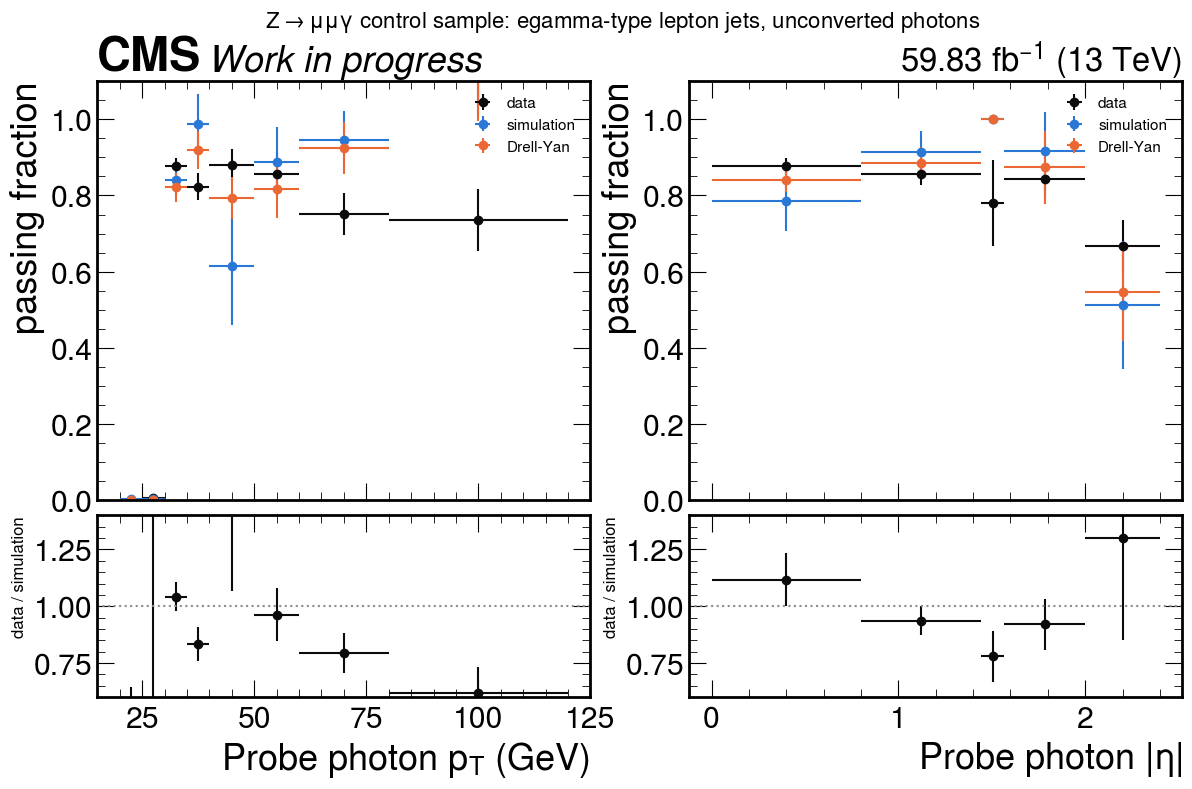

In [6]:
spec = sysstudy.LJ_CR["Z -> mumu gamma"]
dy = sum(sim["background"][s]["Z -> mumu gamma"] for s in sysstudy.LJ_CR_GROUPS[r"DY$\to\ell\ell$"]
         if s in sim["background"])
r9 = {"probe_r9": slice(hist.loc(0.94), None, sum)}
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05})
for col, axis in enumerate(("probe_pt", "probe_abseta")):
    sel = r9 if axis == "probe_pt" else Z_SELECTION
    results = {"data": sysstudy.probe_efficiency(data["Z -> mumu gamma"][sel], spec, axis),
               "simulation": sysstudy.probe_efficiency(sim_total["Z -> mumu gamma"][sel], spec, axis),
               "Drell-Yan": sysstudy.probe_efficiency(dy[sel], spec, axis)}
    sysstudy.plot_efficiency_comparison(results, "simulation", axes[0, col], axes[1, col])
    tables[("Z -> mumu gamma", axis)] = sysstudy.efficiency_table(results, "simulation")
    print(f"Z -> mumu gamma (R9 >= 0.94{'' if axis == 'probe_pt' else ', pT > 30 GeV'}) against {axis}:  data | simulation | data/simulation")
    for lo, hi, d, de, s, se, r, re in tables[("Z -> mumu gamma", axis)]:
        print(f"   {lo:g}-{hi:g}: {d:.3f} +- {de:.3f} | {s:.3f} +- {se:.3f} | {r:.3f} +- {re:.3f}")
# unconverted photons in wider ranges of pT
for name, pt_range in (("above 30 GeV", slice(hist.loc(30), None, sum)), ("30 to 60 GeV", slice(hist.loc(30), hist.loc(60), sum)),
                       ("above 60 GeV", slice(hist.loc(60), None, sum))):
    sel = {"probe_pt": pt_range, **r9}
    values = {label: sysstudy.integrated_efficiency(h[sel], spec) for label, h in
              (("data", data["Z -> mumu gamma"]), ("simulation", sim_total["Z -> mumu gamma"]), ("Drell-Yan", dy))}
    print(f"   unconverted photons {name}: " + ", ".join(f"{k} {e:.3f} +- {u:.3f} ({n:.0f} probes)" for k, (e, u, n) in values.items())
          + f"; data/Drell-Yan {values['data'][0] / values['Drell-Yan'][0]:.3f}")
fig.suptitle(f"{spec['label']} control sample: {spec['lj_type']} lepton jets, unconverted photons", fontsize=16, y=0.97)
pt.cms_label(axes[0], data=True, text="Work in progress")
save(fig, "efficiency_zmmg_data_simulation")
plt.show()

**Interpretation.** For unconverted photons above 30 GeV the passing fraction is 0.854 ± 0.016
in data, 0.842 ± 0.025 in Drell-Yan and 0.820 ± 0.052 in the whole simulation: data/Drell-Yan
**1.01 ± 0.04**, limited by the statistics of the simulation. From 30 to 60 GeV, which holds 90% of
the probes, the ratio is 1.04 ± 0.04; above 60 GeV the data pass in 0.756 ± 0.045 of the cases
against 0.942 ± 0.072 in Drell-Yan (0.80 ± 0.08, a difference of 2.2 standard deviations, from 112
probes in data). Against $|\eta|$ the passing fraction is lowest for $2.0 < |\eta| < 2.4$ in data
and simulation alike.

## 5. What the comparison gives

Written for the run of 2026-11-17 (`lj_reco_cr_data_v1`, `lj_reco_cr_v2`).

1. **Muon-type lepton jets, prompt and collimated.** Above 50 GeV, for opening angles from 0.03 to
   0.12, the simulation describes the passing fraction to about one percent: data/simulation
   0.988 ± 0.006 (0.976 ± 0.008 in the endcaps). This is the regime of the prompt muon-type lepton
   jets of the 5 GeV dark photons, and in part of the 1.2 GeV ones; the lepton jets of the signal
   are mostly above 50 GeV.
2. **Egamma-type lepton jets from unconverted photons.** Above 30 GeV, data/simulation 1.01 ±
   0.04, limited by the statistics of the simulation. Above 60 GeV the data are 0.80 ± 0.08 of the
   simulation, from 112 probes; more probes, or the purer selection that the converted photons
   need anyway, would tell whether this is a trend.
3. **Not measured by these samples:** the displaced DSA muons and the prompt electron pairs
   (question 5 of `lj_reco_efficiency.md`), the converted photons (a purer probe), and the most
   collimated muon pairs (below $\Delta R$ = 0.02 both samples hold few probes; question 4).
4. **For step 3.** The ratios above can become per-lepton-jet scale factors for the prompt regime;
   the granularity (per lepton jet or per constituent) and the treatment of the regimes not
   measured are the group's questions 2 to 5.

The figures and the passing fractions go to EOS, and the local working directory is removed.

In [7]:
with open(WORK / "passing_fractions.json", "w") as f:
    json.dump({f"{cr} | {axis}": [dict(zip(("low", "high", "data", "data_err", "simulation", "simulation_err",
                                            "ratio", "ratio_err"), map(float, row))) for row in table]
               for (cr, axis), table in tables.items()}, f, indent=1)
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_data_v1_results
